# Домашнее задание 1. Сравнение рекомендательных моделей

Датасет: Amazon Reviews 2023, категория Video Games. Модели лежат в папке `models/`, общие функции в `utils.py`.

Запуск:

```
pip install -r requirements.txt
jupyter notebook experiments.ipynb
```

Если файлов нет в `data/`, первая ячейка скачает сама. Seed везде 0.

In [1]:
import gzip
import json
import os
import urllib.request
import warnings

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import torch

from utils import (
    build_matrix,
    temporal_split,
    ground_truth,
    run_eval,
    Popularity,
)
from models.knn import ItemKNN
from models.als import ImplicitALS
from models.ease import EASE
from models.fm import FM
from models.timesvdpp import TimeSVDpp

warnings.filterwarnings("ignore")
SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
pd.set_option("display.precision", 4)

URLS = {
    "data/Video_Games.csv.gz": "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/benchmark/5core/rating_only/Video_Games.csv.gz",
    "data/meta_Video_Games.jsonl.gz": "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/meta_categories/meta_Video_Games.jsonl.gz",
}
os.makedirs("data", exist_ok=True)
for path, url in URLS.items():
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path)

## 1. Данные

Amazon Reviews 2023 (McAuley Lab, UCSD): https://amazon-reviews-2023.github.io/. Категория Video Games, файл `Video_Games.csv.gz` (5-core, только оценки) и метаданные товаров `meta_Video_Games.jsonl.gz`.

Поля оценок: `user_id`, `parent_asin` (id товара), `rating` от 1 до 5, `timestamp` в миллисекундах. Одна строка - один отзыв пользователя на купленный товар, пара пользователь-товар встречается один раз. Из метаданных берем `title`, `categories`, `store` и `details["Date First Available"]`.

Рекомендуем пользователю 10 товаров, с которыми он еще не взаимодействовал. Релевантным считаем товар, который пользователь потом купил и оценил на 4-5. При обучении implicit-моделей положительным сигналом считаются все взаимодействия.

In [2]:
raw = pd.read_csv("data/Video_Games.csv.gz")
raw["dt"] = pd.to_datetime(raw["timestamp"], unit="ms")
print(len(raw), raw["user_id"].nunique(), raw["parent_asin"].nunique())
print(raw["dt"].min(), raw["dt"].max())
raw.head()

814586 94762 25612
1999-10-22 21:43:15 2023-09-02 18:14:28.630000


,user_id,parent_asin,rating,timestamp,dt
0,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B08R5B7YS4,1.0,1611459666223,2021-01-24 03:41:06.223
1,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B0863MT183,4.0,1613701986538,2021-02-19 02:33:06.538
2,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B08P8P7686,5.0,1613702112995,2021-02-19 02:35:12.995
3,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B0B7LV3DN2,4.0,1617641445475,2021-04-05 16:50:45.475
4,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B09WMQ6DXG,5.0,1620231368468,2021-05-05 16:16:08.468


In [3]:
ids = set(raw["parent_asin"])
rows = []
with gzip.open("data/meta_Video_Games.jsonl.gz", "rt") as f:
    for line in f:
        d = json.loads(line)
        if d["parent_asin"] in ids:
            rows.append(
                {
                    "parent_asin": d["parent_asin"],
                    "title": d["title"],
                    "categories": d["categories"],
                    "store": d["store"],
                    "date_first": (d.get("details") or {}).get(
                        "Date First Available"
                    ),
                }
            )
meta = pd.DataFrame(rows)
meta["year"] = (
    meta["date_first"].astype(str).str.extract(r"(\d{4})")[0].astype(float)
)
print(meta.shape)
meta.head()

(25612, 6)


,parent_asin,title,categories,store,date_first,year
0,B00Z9TLVK0,NBA 2K17 - Early Tip Off Edition - PlayStation 4,"[Video Games, PlayStation 4, Games]",2K,"April 13, 2016",2016.0
1,B07H93H878,eXtremeRate Soft Touch Top Shell Front Housing Faceplate Replacement Parts with Side Rails Panel for Xbox One X & One S Controller (Shadow Purple),"[Video Games, Xbox One, Accessories, Faceplates, Protectors & Skins]",eXtremeRate,"September 11, 2017",2017.0
2,B00006969T,Konami Collector's Series: Castlevania & Contra - PC,"[Video Games, PC, Games]",Square Enix,"December 13, 2002",2002.0
3,B07DL353F8,Tales of Vesperia - Definitive Edition - PlayStation 4,"[Video Games, PlayStation 4, Games]",BANDAI NAMCO Entertainment,"June 10, 2018",2018.0
4,B00BJH85SW,Turbo: Super Stunt Squad - Nintendo 3DS,"[Video Games, Legacy Systems, Nintendo Systems, Nintendo 3DS & 2DS]",D3 Publisher,"February 21, 2013",2013.0


## 2. EDA и подготовка

{'user_id': 0, 'parent_asin': 0, 'rating': 0, 'timestamp': 0, 'dt': 0}
дубликаты (user, item): 0


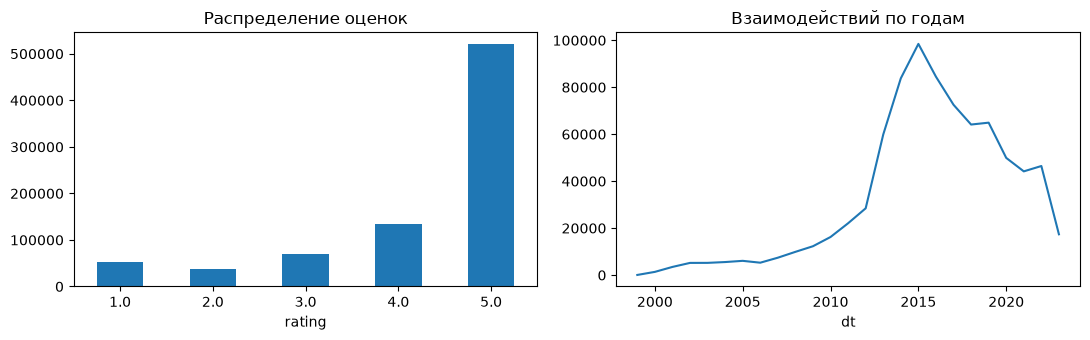

In [4]:
print(raw.isna().sum().to_dict())
print(
    "дубликаты (user, item):", raw.duplicated(["user_id", "parent_asin"]).sum()
)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
raw["rating"].value_counts().sort_index().plot.bar(
    ax=ax[0], title="Распределение оценок", rot=0
)
raw.groupby(raw["dt"].dt.year).size().plot(
    ax=ax[1], title="Взаимодействий по годам"
)
plt.tight_layout()

на пользователя: {'count': 94762.0, 'mean': 8.6, 'std': 7.9, 'min': 5.0, '25%': 5.0, '50%': 6.0, '75%': 9.0, 'max': 473.0}
на товар: {'count': 25612.0, 'mean': 31.8, 'std': 78.0, 'min': 5.0, '25%': 7.0, '50%': 12.0, '75%': 26.0, 'max': 2955.0}
разреженность: 0.99966


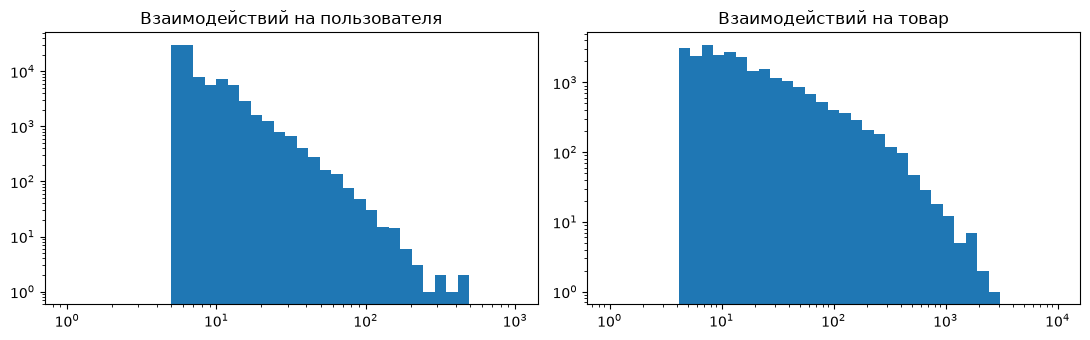

In [5]:
uc = raw["user_id"].value_counts()
ic = raw["parent_asin"].value_counts()
print("на пользователя:", uc.describe().round(1).to_dict())
print("на товар:", ic.describe().round(1).to_dict())
print("разреженность:", round(1 - len(raw) / (len(uc) * len(ic)), 5))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(uc, bins=np.logspace(0, 3, 40))
ax[0].set_xscale("log")
ax[0].set_yscale("log")
ax[0].set_title("Взаимодействий на пользователя")
ax[1].hist(ic, bins=np.logspace(0, 4, 40))
ax[1].set_xscale("log")
ax[1].set_yscale("log")
ax[1].set_title("Взаимодействий на товар")
plt.tight_layout()

{'parent_asin': 0.0, 'title': 0.0, 'categories': 0.0, 'store': 0.005, 'date_first': 0.042, 'year': 0.042}
категорий: 160  магазинов: 3905


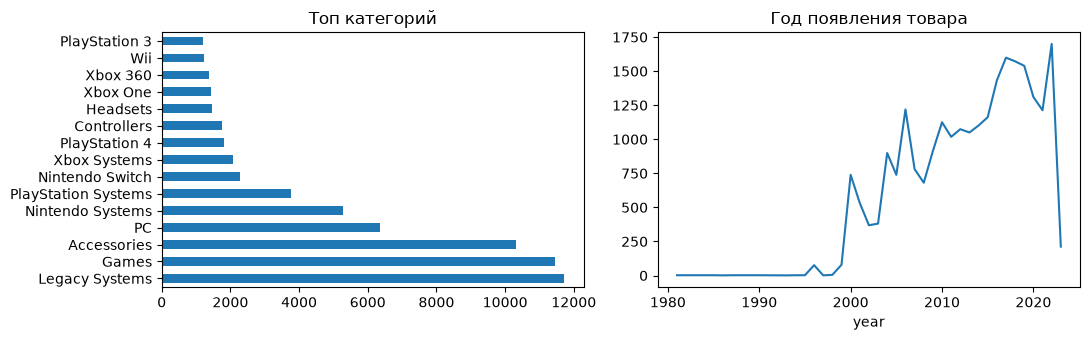

In [6]:
print(meta.isna().mean().round(3).to_dict())
cats = pd.Series(
    [c for cs in meta["categories"] for c in cs if c != "Video Games"]
)
print("категорий:", cats.nunique(), " магазинов:", meta["store"].nunique())
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
cats.value_counts().head(15).plot.barh(ax=ax[0], title="Топ категорий")
meta["year"].dropna().astype(int).value_counts().sort_index().plot(
    ax=ax[1], title="Год появления товара"
)
plt.tight_layout()

Пропусков и дублей в оценках нет. Хвост длинный, у половины товаров не больше 12 оценок, у половины пользователей не больше 6. Оставляем товары хотя бы с 10 оценками и пользователей хотя бы с 5, фильтр повторяем пока ничего не меняется. Редкие товары коллаборативным моделям все равно ничего не дает, зато матрица item-item для EASE становится меньше. Метаданные есть у всех товаров, год появления неизвестен примерно у 4% - для них отдельная категория.

In [7]:
def iterative_filter(d, min_user=5, min_item=10):
    while True:
        n = len(d)
        ic = d["parent_asin"].value_counts()
        d = d[d["parent_asin"].isin(ic[ic >= min_item].index)]
        uc = d["user_id"].value_counts()
        d = d[d["user_id"].isin(uc[uc >= min_user].index)]
        if len(d) == n:
            return d


df = iterative_filter(raw).copy()
df["uid"] = df["user_id"].astype("category").cat.codes.astype(np.int64)
df["iid"] = df["parent_asin"].astype("category").cat.codes.astype(np.int64)
df["day"] = (df["dt"] - pd.Timestamp("1999-01-01")).dt.total_seconds() / 86400
n_users, n_items = int(df["uid"].max()) + 1, int(df["iid"].max()) + 1
items = (
    df[["iid", "parent_asin"]]
    .drop_duplicates()
    .merge(meta, on="parent_asin", how="left")
    .sort_values("iid")
    .reset_index(drop=True)
)
print(
    "итог:",
    len(df),
    "взаимодействий,",
    n_users,
    "пользователей,",
    n_items,
    "товаров, разреженность",
    round(1 - len(df) / (n_users * n_items), 5),
)

итог: 674368 взаимодействий, 79366 пользователей, 13532 товаров, разреженность 0.99937


## 3. Разбиение и метрики

Разбиение по времени, одно для всех моделей: train до 2020-01-01, validation - 2020 год, test с 2021-01-01 до конца данных. Гиперпараметры подбираем по NDCG@10 на validation, потом модель с выбранными настройками обучаем на train + validation и оцениваем на test.

Оцениваем только пользователей, у которых есть история в train и хотя бы один релевантный товар в val/test среди известных товаров. Новых пользователей и новые товары не рассматриваем. Кандидатами считаем все товары из train, кроме тех, с которыми пользователь уже взаимодействовал. Каждая модель выдает top-10 по своим скорам.

Метрики при K = 10, усредняем по пользователям: Recall@10 и NDCG@10. Для сравнения считаем еще бейзлайн Popularity, самые популярные товары из train.

In [8]:
T1, T2 = pd.Timestamp("2020-01-01"), pd.Timestamp("2021-01-01")
train, val, test = temporal_split(df, T1, T2)
trainval = pd.concat([train, val])
print("train", len(train), "val", len(val), "test", len(test))

X_tr = build_matrix(train, n_users, n_items)
R_tr = build_matrix(train, n_users, n_items, "rating")
truth_val = ground_truth(val, train)
X_tv = build_matrix(trainval, n_users, n_items)
R_tv = build_matrix(trainval, n_users, n_items, "rating")
truth_test = ground_truth(test, trainval)
print("пользователей в оценке: val", len(truth_val), " test", len(truth_test))

pop_val = run_eval(Popularity().fit(X_tr), truth_val, X_tr)
pop_val

train 565595 val 38368 test 70405
пользователей в оценке: val 10405  test 12492


{'recall@10': 0.02227495322212966, 'ndcg@10': 0.015059022919903017}

## 4. Модели

### 4.1 Item-based kNN

Бинарная матрица $X$ пользователь-товар. Сходство товаров - косинус с shrinkage $\beta$, который штрафует пары с малым числом общих пользователей: $s_{ij} = \frac{x_i^\top x_j}{\|x_i\| \|x_j\| + \beta}$. Для каждого товара оставляем $k$ ближайших соседей, скор $\hat r_{ui} = \sum_{j \in N_k(i)} x_{uj} s_{ij}$.

Сетка: $k \in \{200, 800, 1600\}$, $\beta \in \{0, 50, 200\}$.

In [9]:
grid = []
for k in [200, 800, 1600]:
    for sh in [0, 50, 200]:
        m = ItemKNN(k=k, shrinkage=sh).fit(X_tr)
        grid.append({"k": k, "shrinkage": sh, **run_eval(m, truth_val, X_tr)})
knn_grid = pd.DataFrame(grid).sort_values("ndcg@10", ascending=False)
knn_grid

,k,shrinkage,recall@10,ndcg@10
8,1600,200,0.0233,0.0146
5,800,200,0.0226,0.0144
7,1600,50,0.0227,0.0143
4,800,50,0.0225,0.0142
2,200,200,0.0229,0.0142
1,200,50,0.0227,0.0140
6,1600,0,0.0203,0.0124
3,800,0,0.0201,0.0123
0,200,0,0.0192,0.0119


### 4.2 iALS

ALS для implicit feedback. Предпочтение $p_{ui} = 1$ если взаимодействие было, иначе 0, уверенность $c_{ui} = 1 + \alpha x_{ui}$. Минимизируем $\sum_{u,i} c_{ui} (p_{ui} - u_u^\top v_i)^2 + \lambda (\sum_u \|u_u\|^2 + \sum_i \|v_i\|^2)$. Попеременно фиксируем одну матрицу и пересчитываем другую, $u_u = (V^\top C_u V + \lambda I)^{-1} V^\top C_u p_u$, 15 итераций, скор $u_u^\top v_i$.

Сетка: $f \in \{32, 64, 128\}$, $\lambda \in \{10, 100\}$, $\alpha \in \{20, 100\}$.

In [10]:
grid = []
for f in [32, 64, 128]:
    for reg in [10, 100]:
        for alpha in [20, 100]:
            m = ImplicitALS(
                factors=f, reg=reg, alpha=alpha, iterations=15, seed=SEED
            ).fit(X_tr)
            grid.append(
                {
                    "factors": f,
                    "reg": reg,
                    "alpha": alpha,
                    **run_eval(m, truth_val, X_tr),
                }
            )
als_grid = pd.DataFrame(grid).sort_values("ndcg@10", ascending=False)
als_grid

,factors,reg,alpha,recall@10,ndcg@10
7,64,100,100,0.0263,0.0159
11,128,100,100,0.0251,0.0156
5,64,10,100,0.0253,0.0155
4,64,10,20,0.0249,0.0152
3,32,100,100,0.0246,0.0146
6,64,100,20,0.0225,0.0144
1,32,10,100,0.0245,0.0144
0,32,10,20,0.0239,0.0143
2,32,100,20,0.0229,0.0141
8,128,10,20,0.0224,0.0138


### 4.3 EASE

Линейная модель item-item: $\min_B \|X - XB\|_F^2 + \lambda \|B\|_F^2$ при $\mathrm{diag}(B) = 0$. Решение в замкнутом виде: $P = (X^\top X + \lambda I)^{-1}$, $B_{ij} = -P_{ij} / P_{jj}$, $B_{jj} = 0$, строка $x_u^\top B$ и есть скоры пользователя.

Сетка: $\lambda \in \{20, 50, 100, 200, 500, 1000\}$.

In [11]:
grid = []
for reg in [20, 50, 100, 200, 500, 1000]:
    m = EASE(reg=reg).fit(X_tr)
    grid.append({"reg": reg, **run_eval(m, truth_val, X_tr)})
ease_grid = pd.DataFrame(grid).sort_values("ndcg@10", ascending=False)
ease_grid

,reg,recall@10,ndcg@10
1,50,0.0251,0.0160
2,100,0.0243,0.0158
3,200,0.0252,0.0158
0,20,0.0245,0.0157
4,500,0.0247,0.0155
5,1000,0.0246,0.0153


### 4.4 FM с метапризнаками

Факторизационная машина второго порядка на векторе признаков $x = [x^{(u)}; x^{(i)}]$: $\hat y(x) = w_0 + \sum_f w_f x_f + \frac12 \sum_{d=1}^{k} [(\sum_f v_{fd} x_f)^2 - \sum_f v_{fd}^2 x_f^2]$.

Признаки пользователя: id и число взаимодействий в train. Признаки товара: id, категории из `categories` (multi-hot), `store` и год появления бинами по 4 года. Магазины, у которых меньше 5 товаров, слиты в один other.

Обучение парное (BPR): для каждого взаимодейтсвия $(u, i)$ берем случайный товар $j$ без взаимодействия и минимизируем $-\log \sigma(\hat y(u, i) - \hat y(u, j))$ плюс L2 на параметры, Adam, батч 4096. Скор $\hat y(u, i)$.

Сетка: $k \in \{16, 32, 64\}$, $\lambda \in \{0.001, 0.01\}$, эпохи $\in \{3, 10\}$, lr = 0.005.

In [12]:
def item_feature_matrix(items):
    n = len(items)
    rows, cols, vals = list(range(n)), list(range(n)), [1.0] * n
    col = n
    cat_idx = {}
    for i, cs in enumerate(items["categories"]):
        cs = [c for c in cs if c != "Video Games"]
        for c in cs:
            cat_idx.setdefault(c, len(cat_idx))
            rows.append(i)
            cols.append(col + cat_idx[c])
            vals.append(1.0 / len(cs))
    col += len(cat_idx)
    counts = items["store"].value_counts()
    store_idx = {}
    for i, s in enumerate(items["store"]):
        s = s if counts.get(s, 0) >= 5 else "other"
        store_idx.setdefault(s, len(store_idx))
        rows.append(i)
        cols.append(col + store_idx[s])
        vals.append(1.0)
    col += len(store_idx)
    yb = np.where(
        items["year"].isna(),
        6,
        np.clip((items["year"].fillna(2000) - 2000) // 4, 0, 5),
    )
    for i, b in enumerate(yb):
        rows.append(i)
        cols.append(col + int(b))
        vals.append(1.0)
    col += 7
    return sp.csr_matrix((vals, (rows, cols)), shape=(n, col))


def user_feature_matrix(X):
    n = X.shape[0]
    bucket = np.clip(np.log2(np.maximum(X.getnnz(axis=1), 1)).astype(int), 0, 5)
    act = sp.csr_matrix((np.ones(n), (np.arange(n), bucket)), shape=(n, 6))
    return sp.hstack([sp.identity(n, format="csr"), act]).tocsr()


IF = item_feature_matrix(items)
UF_tr = user_feature_matrix(X_tr)
print("признаков товара:", IF.shape[1], " пользователя:", UF_tr.shape[1])

признаков товара: 14007  пользователя: 79372


In [13]:
grid = []
for f in [16, 32, 64]:
    for reg in [1e-3, 1e-2]:
        for epochs in [3, 10]:
            m = FM(factors=f, reg=reg, epochs=epochs, lr=0.005, seed=SEED).fit(
                X_tr, UF_tr, IF
            )
            grid.append(
                {
                    "factors": f,
                    "reg": reg,
                    "epochs": epochs,
                    **run_eval(m, truth_val, X_tr),
                }
            )
fm_grid = pd.DataFrame(grid).sort_values("ndcg@10", ascending=False)
fm_grid

,factors,reg,epochs,recall@10,ndcg@10
2,16,0.010,3,0.0248,0.0174
6,32,0.010,3,0.0254,0.0172
10,64,0.010,3,0.0248,0.0165
4,32,0.001,3,0.0237,0.0162
3,16,0.010,10,0.0247,0.0162
8,64,0.001,3,0.0229,0.0156
7,32,0.010,10,0.0242,0.0155
0,16,0.001,3,0.0219,0.0155
11,64,0.010,10,0.0233,0.0148
1,16,0.001,10,0.0228,0.0145


### 4.5 timeSVD++

timeSVD++ предсказывает оценку и учитывает время: $\hat r_{ui}(t) = \mu + b_u + \alpha_u \mathrm{dev}_u(t) + b_i + b_{i,\mathrm{Bin}(t)} + q_i^\top (p_u + |N(u)|^{-1/2} \sum_{j \in N(u)} y_j)$, где $\mathrm{dev}_u(t) = \mathrm{sign}(t - t_u) |t - t_u|^{0.4}$, $t$ в днях, $t_u$ - средняя дата оценок пользователя, $\mathrm{Bin}(t)$ - один из 30 равных бинов обучающего периода, $N(u)$ - товары, которые пользователь оценил. Минимизируем MSE по оценкам train с L2-регуляризацией, у $\alpha_u$ свой коэффициент $\lambda_\alpha$, Adam, 15 эпох. Дневное смещение $b_{u,t}$ не используем.

Для рекомендаций берем $\hat r_{ui}(t_0)$, где $t_0$ - начало тестового периода, то есть последний бин.

Сетка: $f \in \{32, 64\}$, $\lambda \in \{0.5, 2.0\}$, $\lambda_\alpha \in \{100, 400\}$, lr = 0.003.

In [14]:
D_tr = build_matrix(train, n_users, n_items, "day")
D_tv = build_matrix(trainval, n_users, n_items, "day")
day_val = (T1 - pd.Timestamp("1999-01-01")).days
day_test = (T2 - pd.Timestamp("1999-01-01")).days
grid = []
for f in [32, 64]:
    for reg in [0.5, 2.0]:
        for reg_alpha in [100, 400]:
            m = TimeSVDpp(
                factors=f,
                reg=reg,
                reg_alpha=reg_alpha,
                lr=0.003,
                epochs=15,
                n_bins=30,
                seed=SEED,
            ).fit(R_tr, D_tr)
            grid.append(
                {
                    "factors": f,
                    "reg": reg,
                    "reg_alpha": reg_alpha,
                    **run_eval(m, truth_val, X_tr, day=day_val),
                }
            )
tsvd_grid = pd.DataFrame(grid).sort_values("ndcg@10", ascending=False)
tsvd_grid

,factors,reg,reg_alpha,recall@10,ndcg@10
3,32,2.0,400,0.0040,0.0022
7,64,2.0,400,0.0040,0.0022
0,32,0.5,100,0.0031,0.0020
2,32,2.0,100,0.0035,0.0019
4,64,0.5,100,0.0029,0.0019
6,64,2.0,100,0.0035,0.0019
1,32,0.5,400,0.0024,0.0018
5,64,0.5,400,0.0023,0.0017


## 5. Сравнение на test

Берем лучшие по validation настройки из сеток выше, обучаем на train + validation и оцениваем на test. Плюс FM только на id пользователя и товара с теми же настройками чтобы понять вклад метапризнаков.

In [15]:
best_knn, best_als, best_ease, best_fm, best_tsvd = (
    knn_grid.iloc[0],
    als_grid.iloc[0],
    ease_grid.iloc[0],
    fm_grid.iloc[0],
    tsvd_grid.iloc[0],
)
metrics = ["recall@10", "ndcg@10"]
val_best = pd.DataFrame(
    [pop_val, best_knn, best_als, best_ease, best_fm, best_tsvd],
    index=["Popularity", "ItemKNN", "iALS", "EASE", "FM", "timeSVD++"],
)[metrics]
val_best

,recall@10,ndcg@10
Popularity,0.0223,0.0151
ItemKNN,0.0233,0.0146
iALS,0.0263,0.0159
EASE,0.0251,0.0160
FM,0.0248,0.0174
timeSVD++,0.0040,0.0022


In [16]:
UF_tv = user_feature_matrix(X_tv)
final = {}
final["Popularity"] = run_eval(Popularity().fit(X_tv), truth_test, X_tv)

knn = ItemKNN(k=int(best_knn["k"]), shrinkage=float(best_knn["shrinkage"])).fit(
    X_tv
)
final["ItemKNN"] = run_eval(knn, truth_test, X_tv)

als = ImplicitALS(
    factors=int(best_als["factors"]),
    reg=float(best_als["reg"]),
    alpha=float(best_als["alpha"]),
    iterations=15,
    seed=SEED,
).fit(X_tv)
final["iALS"] = run_eval(als, truth_test, X_tv)

ease = EASE(reg=float(best_ease["reg"])).fit(X_tv)
final["EASE"] = run_eval(ease, truth_test, X_tv)

fm_params = dict(
    factors=int(best_fm["factors"]),
    reg=float(best_fm["reg"]),
    epochs=int(best_fm["epochs"]),
    lr=0.005,
    seed=SEED,
)
fm = FM(**fm_params).fit(X_tv, UF_tv, IF)
final["FM"] = run_eval(fm, truth_test, X_tv)
fm_id = FM(**fm_params).fit(
    X_tv, sp.identity(n_users, format="csr"), sp.identity(n_items, format="csr")
)
final["FM (только id)"] = run_eval(fm_id, truth_test, X_tv)

tsvd = TimeSVDpp(
    factors=int(best_tsvd["factors"]),
    reg=float(best_tsvd["reg"]),
    reg_alpha=float(best_tsvd["reg_alpha"]),
    lr=0.003,
    epochs=15,
    n_bins=30,
    seed=SEED,
).fit(R_tv, D_tv)
final["timeSVD++"] = run_eval(tsvd, truth_test, X_tv, day=day_test)

test_table = pd.DataFrame(final).T
test_table

,recall@10,ndcg@10
Popularity,0.0144,0.0092
ItemKNN,0.0199,0.0125
iALS,0.0209,0.0131
EASE,0.0203,0.0134
FM,0.0196,0.0121
FM (только id),0.0169,0.0109
timeSVD++,0.0072,0.0035


In [17]:
pd.set_option("display.max_colwidth", None)
params = pd.Series(
    {
        "ItemKNN": f"k={int(best_knn['k'])}, shrinkage={best_knn['shrinkage']}",
        "iALS": f"factors={int(best_als['factors'])}, reg={best_als['reg']}, alpha={best_als['alpha']}, iterations=15",
        "EASE": f"reg={best_ease['reg']}",
        "FM": f"factors={int(best_fm['factors'])}, reg={best_fm['reg']}, epochs={int(best_fm['epochs'])}, lr=0.005",
        "timeSVD++": f"factors={int(best_tsvd['factors'])}, reg={best_tsvd['reg']}, reg_alpha={best_tsvd['reg_alpha']}, n_bins=30, epochs=15, lr=0.003",
    },
    name="гиперпараметры",
).to_frame()
params

,гиперпараметры
ItemKNN,"k=1600, shrinkage=200.0"
iALS,"factors=64, reg=100.0, alpha=100.0, iterations=15"
EASE,reg=50.0
FM,"factors=16, reg=0.01, epochs=3, lr=0.005"
timeSVD++,"factors=32, reg=2.0, reg_alpha=400.0, n_bins=30, epochs=15, lr=0.003"


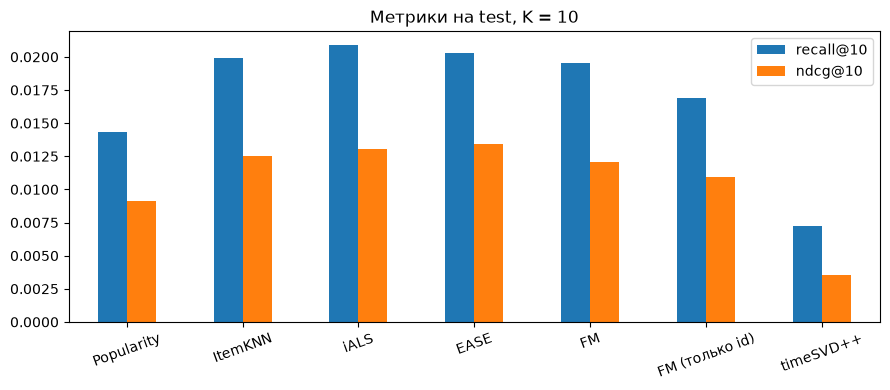

In [18]:
ax = test_table.plot.bar(
    figsize=(9, 4), rot=20, title="Метрики на test, K = 10"
)
plt.tight_layout()

## 6. Выводы

На test лучше всех EASE, за ней iALS, у которой зато лучший Recall@10, потом ItemKNN и FM. NDCG@10 у всех четырех примерно 0.012-0.013 против 0.009 у Popularity, между собой EASE, iALS и ItemKNN различаются в третьем знаке, с одним разбиением это ничего не значит. На validation лучшей была FM с NDCG@10 0.017, на test она оказалась ниже остальных трех, у нее победили маленькая размерность и 3 эпохи, 10 эпох везде хуже 3. Еще на validation Popularity по NDCG@10 чуть обогнал ItemKNN, на test уже нет.

FM только на id с теми же настройками дает NDCG@10 0.011 против 0.012 и Recall@10 0.017 против 0.020, то есть метапризнаки помогают.

У ItemKNN лучше работают большие k и ненулевой shrinkage, без него качество заметно падает. У iALS лучше большие alpha и reg, у EASE оптимум по reg = 50.

timeSVD++ для top-10 не подходит, NDCG@10 всего 0.0035, хуже Popularity. Она предсказывает оценку, а не факт покупки так что высокий скор получают и товары, которые почти никто не покупал.